# Dimensionality of the Go / No-Go population code in the RNNs

Network version of the A1 analysis (PCA geometry + participation ratio). For every model and checkpoint (checkpoint step stands in for training day):

* **Sessions**: independent simulations (own trial draw and noise) of one checkpoint. They are repeated measurements of one network, *not* independent animals, so p-values describe session-to-session variability only.
* **Units**: responsive units only (`responsive_criteria.json`), Z-scored; trials aligned to their own stimulus onset.
* **PCA geometry**: Go and No-Go condition-mean trajectories (0–300 ms) stacked into a [2T × N] matrix, top 3 PCs.
* **Participation ratio** PR = (Σλ)² / Σλ², λ = eigenvalues of the unit × unit covariance across trials (each trial = response averaged over 0–300 ms); nPR = PR / N responsive units. Also: fraction of variance in the first covariance PC and an entropy-based effective dimension (the paper's "different measure").

In [29]:
import importlib
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, mannwhitneyu

sys.path.insert(0, os.getcwd())
import neuron_discrimination as nd
import population_geometry as pg
# pick up edits to the helper modules without restarting the kernel (nd first: pg imports from it)
importlib.reload(nd)
importlib.reload(pg)
%matplotlib inline

In [30]:
# ── set up ────────────────────────────────────────────────────────────────
env_file = Path.cwd().parent / '.env'
if env_file.exists():
    for line in env_file.read_text().splitlines():
        line = line.strip()
        if '=' in line and not line.startswith('#'):
            key, _, val = line.partition('=')
            os.environ.setdefault(key.strip(), val.strip())

results_dir = Path(os.environ.get('TONE_RESULTS_DIR', ''))
if not results_dir:
    sys.exit('TONE_RESULTS_DIR is not set. Add it to .env or export it.')

# model groups: label -> model dir and the stimulus set it is tested on
RUNS = {
    'PT':     dict(model_dir=results_dir / 'pure/pure_0_lr0.0001_bs64_noise0.1_nrnn128', task='pure', checkpoint=4000),
    'HCT':    dict(model_dir=results_dir / 'harmonic/harmonic_0_lr0.0001_bs64_noise0.1_nrnn128', task='harmonic', checkpoint=4000),
    'PT-HCT': dict(model_dir=results_dir / 'transfer_pure_to_harmonic/all/harmonic/harmonic_0_lr1e-05_bs64_noise0.1_nrnn128_src15000', task='harmonic', checkpoint=200),
}

N_STEPS     = 8      # checkpoints per model (spread over training, plus step 0)
N_SESSIONS  = 10     # simulated sessions per checkpoint
N_TRIALS    = 200    # trials per session
WINDOW_MS   = (0, 300)       # response window (ms from stimulus onset)
ZSCORE      = 'all'          # 'all' | 'baseline' | None  (see neuron_discrimination.select_units)
RESPONSIVE_ONLY = True       # True: responsive units only; False: all units

# group comparison (final checkpoints) and before / after-switch panel
GROUP_A, GROUP_B = 'HCT', 'PT-HCT'
SWITCH_MODEL, SOURCE_TASK = 'PT-HCT', 'pure'   # transferred model and the task it came from
START_STEP = 200     # checkpoint step of SWITCH_MODEL that counts as "start of training" in the
                     # before / after panel (0 = initial weights; must be an available checkpoint)

# "day 3" of the paper = early training, before the transfer (PT phase)
DAY3_STEP  = 4000     # checkpoint step that counts as day 3 (nearest available checkpoint is used);
                     # used for the early-training PT vs HCT comparison and the "before transfer" point
SOURCE_RUN = 'PT'    # RUNS entry that SWITCH_MODEL was transferred from; its network at DAY3_STEP,
                     # tested on its own task, is the "before transfer" state in the before / after panel
SHOW = 3             # checkpoints shown per model in the trajectory figure

# Go / No-Go separating dimension (noisy-trajectory PCA and separating-dimension analyses)
SEP_AFTER_OFF_MS = (0, None)  # window AFTER stimulus offset (ms from offset; end None = end of trial)
                              # in which the dimension that best separates Go from No-Go is extracted
N_SHOW_TRIALS = 20            # single-trial trajectories drawn per class in the noisy-trajectory figure
CUTOFF_MS = None              # analyse only this many ms after go-cue (stimulus) onset; None = whole trial

In [31]:
kw = dict(n_sessions=N_SESSIONS, n_trials=N_TRIALS, window_ms=WINDOW_MS,
          zscore=ZSCORE, responsive_only=RESPONSIVE_ONLY,
          sep_after_off_ms=SEP_AFTER_OFF_MS, n_show_trials=N_SHOW_TRIALS, cutoff_ms=CUTOFF_MS)

def comparison_step(label):
    """Checkpoint used for the group comparison: RUNS[label]['checkpoint'] or the last one."""
    ck = RUNS[label].get('checkpoint')
    return int(ck) if ck is not None else int(max(s for s, _ in pg._list_checkpoints(RUNS[label]['model_dir'])))

def nearest_step(label, step):
    """Available checkpoint of RUNS[label] closest to `step` (0 = initial weights)."""
    avail = [0] + [s for s, _ in pg._list_checkpoints(RUNS[label]['model_dir'])]
    return int(min(avail, key=lambda s: abs(s - step)))

# "day 3" checkpoint of every run
day3 = {l: nearest_step(l, DAY3_STEP) for l in RUNS}
for l, s in day3.items():
    if s != DAY3_STEP:
        print(f'note: {l} has no checkpoint at step {DAY3_STEP}; using step {s} as day 3')

rows = []
for label, cfg in RUNS.items():
    steps = sorted(set(pg.pick_steps(cfg['model_dir'], N_STEPS)) | {comparison_step(label), day3[label]})
    rows += pg.run_condition(label, cfg['model_dir'], cfg['task'], steps, **kw)
df = pd.DataFrame(rows)

# before / after the switch for the transferred model:
#   day 3 (before transfer): the source network (SOURCE_RUN) at its day-3 checkpoint on its own task
#   start: SWITCH_MODEL at START_STEP on the source task and on the new task
#   after transfer: SWITCH_MODEL at its comparison checkpoint on the new task
sw  = RUNS[SWITCH_MODEL]
src = RUNS[SOURCE_RUN]
last_sw = comparison_step(SWITCH_MODEL)
switch_conds = [
    (f'before transfer: day 3 (step {day3[SOURCE_RUN]}) | {src["task"]}', src['model_dir'], day3[SOURCE_RUN], src['task']),
    (f'start (step {START_STEP}) | {SOURCE_TASK}',                       sw['model_dir'],  START_STEP,        SOURCE_TASK),
    (f'start (step {START_STEP}) | {sw["task"]}',                        sw['model_dir'],  START_STEP,        sw['task']),
    (f'after transfer (step {last_sw}) | {sw["task"]}',                  sw['model_dir'],  last_sw,           sw['task']),
]
switch_rows = []
for lab, mdir, step, task in switch_conds:
    switch_rows += pg.run_condition(lab, mdir, task, [step], **kw)
df_switch = pd.DataFrame(switch_rows)

  step 0: NO checkpoint_init.pkl in C:\Users\zhixi\Documents\data\results\tone_generalize\pure\pure_0_lr0.0001_bs64_noise0.1_nrnn128 -> using a random network built from its config.json
        PT step      0 pure       PR=19.43  nPR=0.297  units=66  hit=0.00  FA=0.00
        PT step    200 pure       PR=16.52  nPR=0.322  units=51  hit=0.04  FA=0.02
        PT step   2400 pure       PR= 3.43  nPR=0.064  units=54  hit=0.71  FA=0.00
        PT step   4000 pure       PR= 3.51  nPR=0.060  units=58  hit=0.92  FA=0.00
        PT step   4400 pure       PR= 3.52  nPR=0.059  units=60  hit=0.96  FA=0.00
        PT step   6600 pure       PR= 3.21  nPR=0.049  units=66  hit=0.99  FA=0.00
        PT step   8600 pure       PR= 2.62  nPR=0.039  units=67  hit=1.00  FA=0.00
        PT step  10800 pure       PR= 2.21  nPR=0.032  units=68  hit=1.00  FA=0.00
        PT step  12800 pure       PR= 1.99  nPR=0.029  units=68  hit=1.00  FA=0.00
        PT step  15000 pure       PR= 1.91  nPR=0.027  units=70  hi

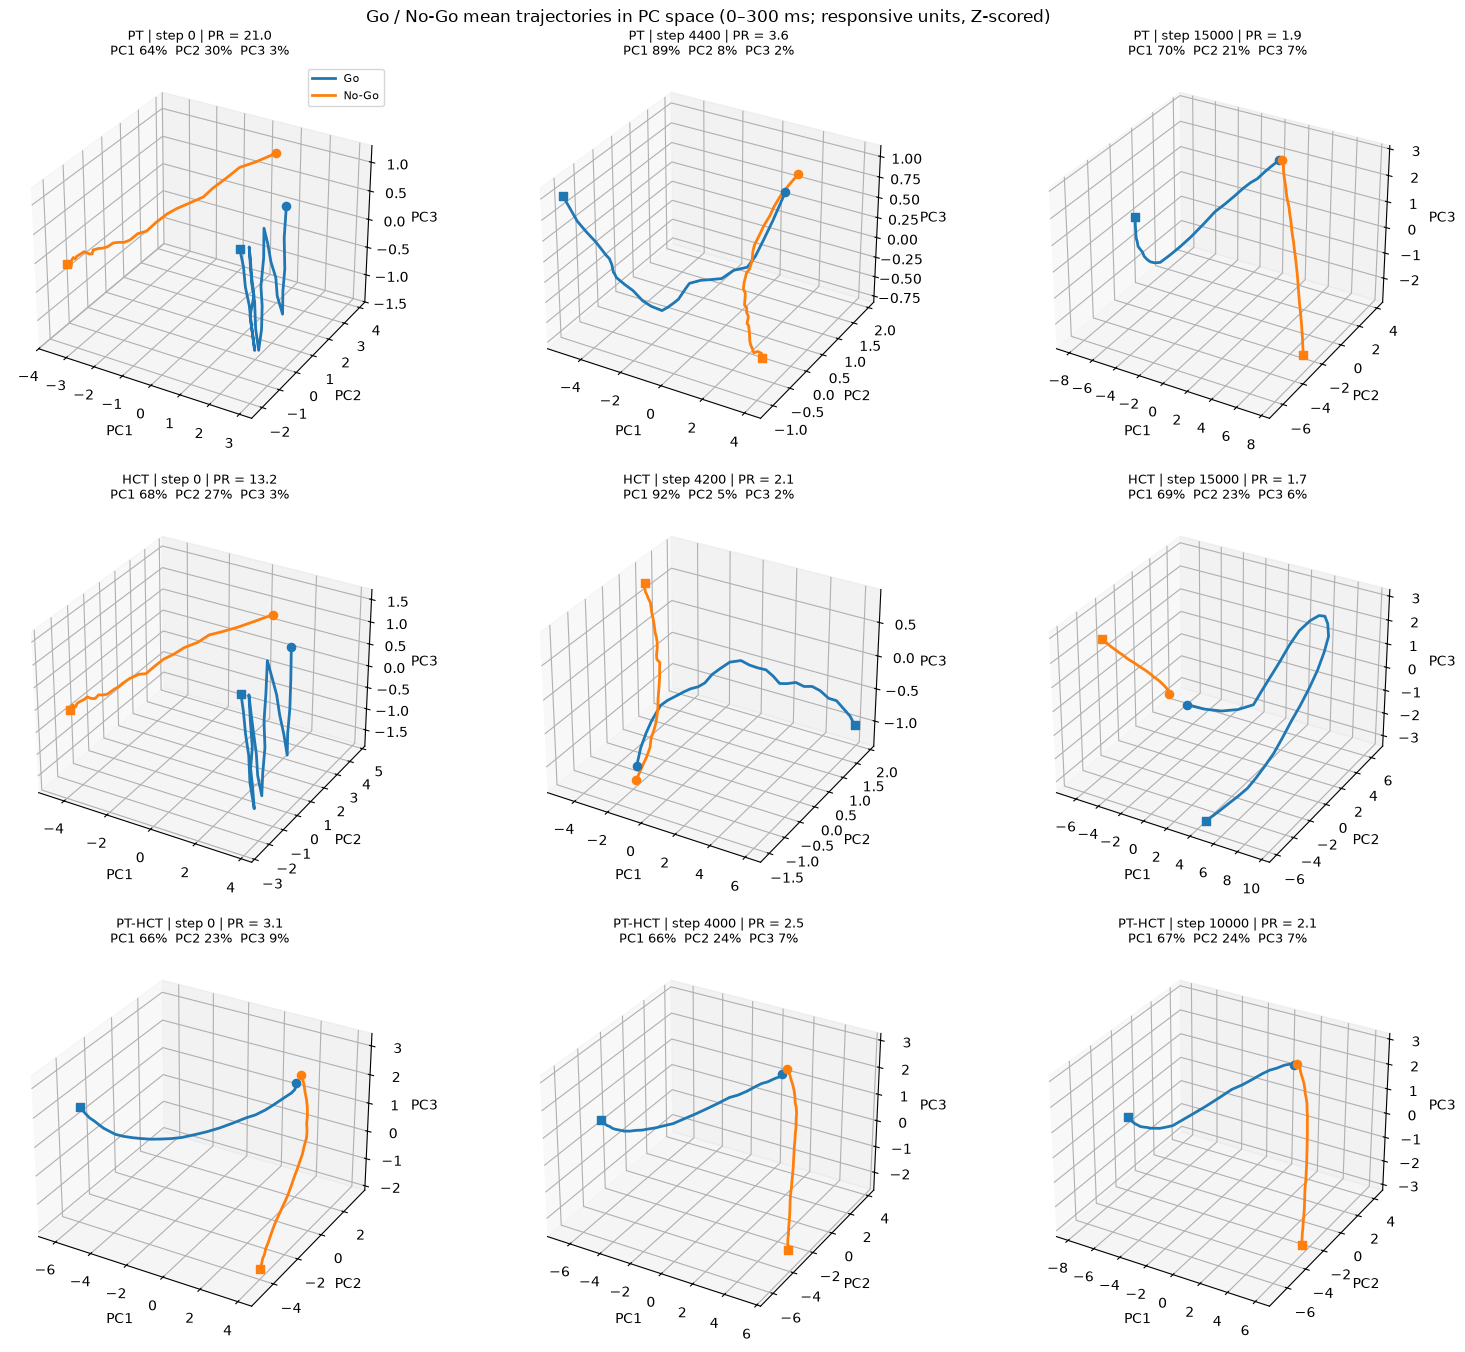

In [32]:
# ── PCA geometry: Go / No-Go mean trajectories (session 0) at early / mid / late checkpoints ──
fig = plt.figure(figsize=(5.2 * SHOW, 4.6 * len(RUNS)))
for i, label in enumerate(RUNS):
    d = df[df['label'] == label]
    steps_l = sorted(d['step'].unique())
    show_steps = [steps_l[j] for j in np.unique(np.round(np.linspace(0, len(steps_l) - 1, SHOW)).astype(int))]
    for j, step in enumerate(show_steps):
        r = d[d['step'] == step].iloc[0]
        ax = fig.add_subplot(len(RUNS), SHOW, i * SHOW + j + 1, projection='3d')
        for proj, col, lab in [(r['proj_go'], 'tab:blue', 'Go'), (r['proj_nogo'], 'tab:orange', 'No-Go')]:
            ax.plot(proj[:, 0], proj[:, 1], proj[:, 2], color=col, lw=2, label=lab)
            ax.scatter(*proj[0], color=col, marker='o', s=35)      # circle = onset
            ax.scatter(*proj[-1], color=col, marker='s', s=35)     # square = end of window
        v = r['var_ratio'] * 100
        ax.set_title(f'{label} | step {step} | PR = {r["pr"]:.1f}\n'
                     f'PC1 {v[0]:.0f}%  PC2 {v[1]:.0f}%  PC3 {v[2]:.0f}%', fontsize=9)
        ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_zlabel('PC3')
        if i == 0 and j == 0:
            ax.legend(fontsize=8)
fig.suptitle(f'Go / No-Go mean trajectories in PC space ({WINDOW_MS[0]}–{WINDOW_MS[1]} ms; responsive units, Z-scored)')
fig.tight_layout()
plt.show()

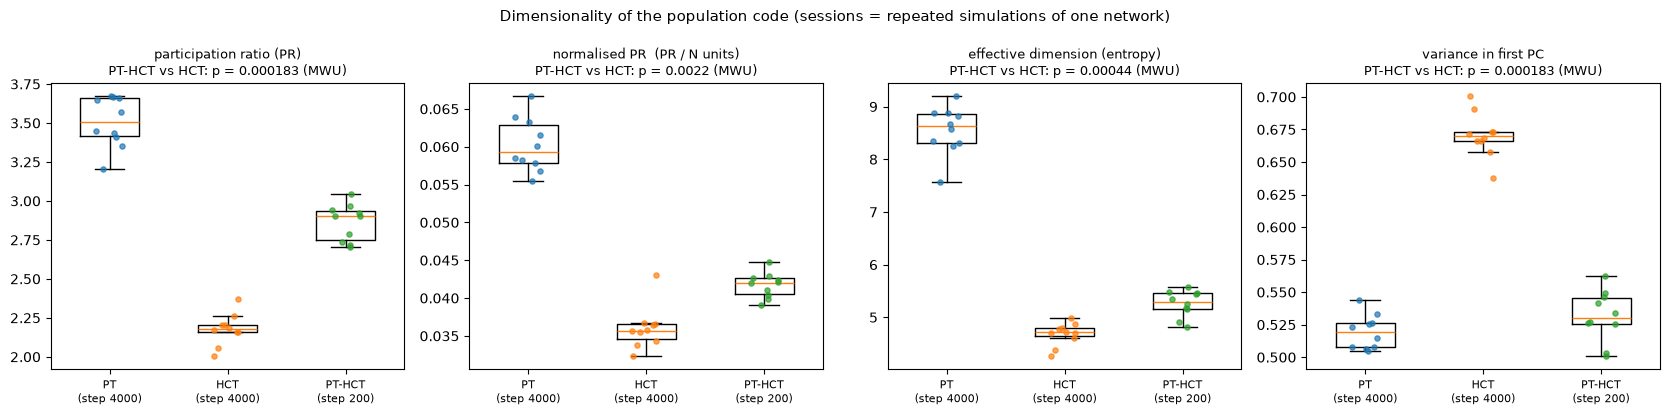

,HCT,PT-HCT,PT-HCT - HCT,p_welch,p_mannwhitney
metric,,,,,
pr,2.177056,2.862794,0.685738,5.398905e-11,0.000183
npr,0.036010,0.041734,0.005724,7.001517e-05,0.002202
eff_dim,4.683208,5.262578,0.579371,3.066576e-05,0.000440
pc1_frac,0.670484,0.531570,-0.138914,2.316065e-12,0.000183


In [33]:
# ── group comparison at each model's comparison checkpoint (RUNS[label]['checkpoint']) ──
last_step = {l: comparison_step(l) for l in RUNS}
dfl = pd.concat([df[(df['label'] == l) & (df['step'] == last_step[l])] for l in RUNS])

metrics = [('pr', 'participation ratio (PR)'), ('npr', 'normalised PR  (PR / N units)'),
           ('eff_dim', 'effective dimension (entropy)'), ('pc1_frac', 'variance in first PC')]
labels = list(RUNS)
fig, axes = plt.subplots(1, len(metrics), figsize=(4.2 * len(metrics), 4.2))
stat_rows = []
for ax, (m, title) in zip(axes, metrics):
    data = [dfl[dfl['label'] == l][m].values for l in labels]
    bp = ax.boxplot(data, positions=range(len(labels)), widths=0.5, showfliers=False)
    rng = np.random.default_rng(0)
    for k, v in enumerate(data):
        ax.scatter(k + rng.uniform(-0.12, 0.12, len(v)), v, s=14, alpha=0.7, zorder=3)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels([f'{l}\n(step {last_step[l]})' for l in labels], fontsize=8)
    a = dfl[dfl['label'] == GROUP_A][m].values
    b = dfl[dfl['label'] == GROUP_B][m].values
    p_t = ttest_ind(b, a, equal_var=False).pvalue
    p_u = mannwhitneyu(b, a, alternative='two-sided').pvalue
    stat_rows.append(dict(metric=m, **{GROUP_A: a.mean(), GROUP_B: b.mean()},
                          **{f'{GROUP_B} - {GROUP_A}': b.mean() - a.mean()},
                          p_welch=p_t, p_mannwhitney=p_u))
    ax.set_title(f'{title}\n{GROUP_B} vs {GROUP_A}: p = {p_u:.3g} (MWU)', fontsize=9)
fig.suptitle('Dimensionality of the population code (sessions = repeated simulations of one network)', fontsize=11)
fig.tight_layout()
plt.show()
pd.DataFrame(stat_rows).set_index('metric')

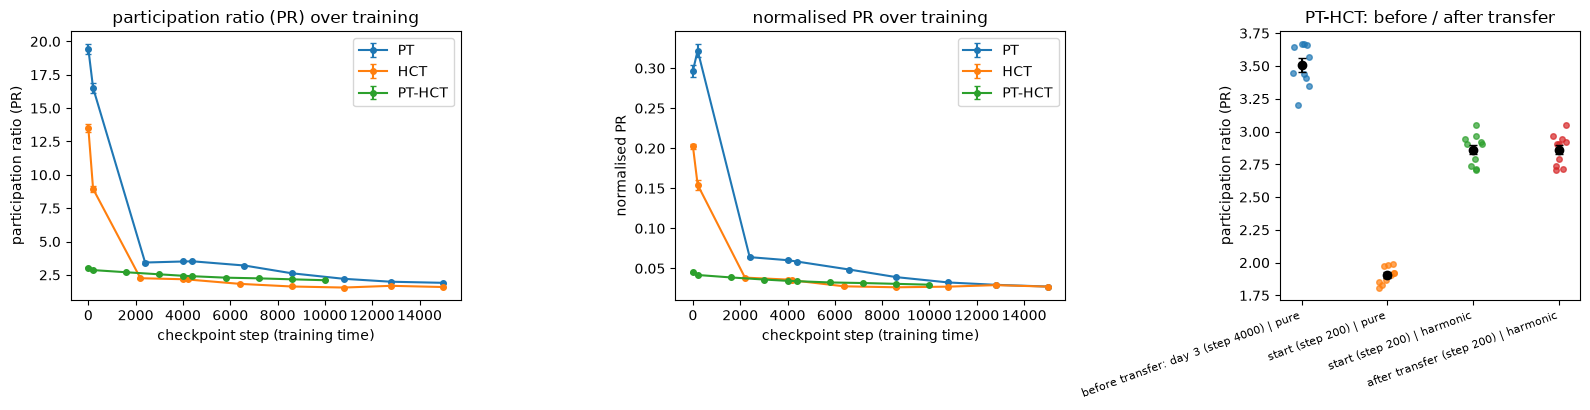

pr    npr  eff_dim  pc1_frac  n_units
label  step                                            
HCT    0      13.501  0.202   34.112     0.248     66.7
       200     8.949  0.154   25.334     0.316     58.2
       2200    2.254  0.038    5.406     0.661     58.7
       4000    2.177  0.036    4.683     0.670     60.6
       4200    2.158  0.035    4.603     0.673     61.6
       6400    1.831  0.028    3.544     0.733     66.5
       8600    1.633  0.026    3.010     0.780     61.9
       10800   1.554  0.027    2.677     0.798     57.2
       12800   1.684  0.029    2.747     0.758     58.0
       15000   1.593  0.027    2.526     0.782     58.6
PT     0      19.433  0.297   39.187     0.191     65.6
       200    16.517  0.322   31.913     0.207     51.4
       2400    3.429  0.064    9.432     0.531     53.6
       4000    3.507  0.060    8.550     0.519     58.3
       4400    3.521  0.059    8.242     0.516     60.3
       6600    3.205  0.049    7.100     0.539     66.0
       8600    2.623  0.039    5.775     0.602     67.2
       10800   2.209  0.032    4.644     0.660     68.2
       12800   1.990  0.029    3.809     0.695     67.5
       15000   1.908  0.027    3.408     0.708     69.9
PT-HCT 0       3.054  0.045    5.882     0.518     67.6
       200     2.863  0.042    5.263     0.532     68.6
       1600    2.700  0.039    4.970     0.557     69.8
       3000    2.546  0.036    4.823     0.589     70.6
       4000    2.436  0.034    4.650     0.609     70.8
       4400    2.403  0.034    4.616     0.616     70.7
       5800    2.294  0.032    4.417     0.636     70.8
       7200    2.244  0.032    4.304     0.645     70.8
       8600    2.171  0.031    4.147     0.658     70.8
       10000   2.103  0.030    4.002     0.671     71.0

In [ ]:
# ── PR over training (checkpoint step) and the before / after-switch comparison ──
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={'width_ratios': [1.3, 1.3, 1]})
sem = lambda v: v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else 0.0
for ax, (m, title) in zip(axes[:2], [('pr', 'participation ratio (PR)'), ('npr', 'normalised PR')]):
    for label in RUNS:
        g = df[df['label'] == label].groupby('step')[m]
        mu, se = g.mean(), g.apply(sem)
        ax.errorbar(mu.index, mu.values, yerr=se.values, marker='o', ms=4, capsize=2, label=label)
    ax.set(xlabel='checkpoint step (training time)', ylabel=title, title=f'{title} over training')
    ax.legend()

ax = axes[2]
names = list(df_switch['label'].unique())
rng = np.random.default_rng(0)
for k, nme in enumerate(names):
    v = df_switch[df_switch['label'] == nme]['pr'].values  
    ax.scatter(k + rng.uniform(-0.1, 0.1, len(v)), v, s=16, alpha=0.7)
    ax.errorbar(k, v.mean(), yerr=sem(v), fmt='o', color='k', ms=6, capsize=3, zorder=4)
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=20, ha='right', fontsize=8)
ax.set(ylabel='participation ratio (PR)', title=f'{SWITCH_MODEL}: before / after transfer')
fig.tight_layout()
plt.show()

(df.groupby(['label', 'step'])[['pr', 'npr', 'eff_dim', 'pc1_frac', 'n_units']].mean().round(3))

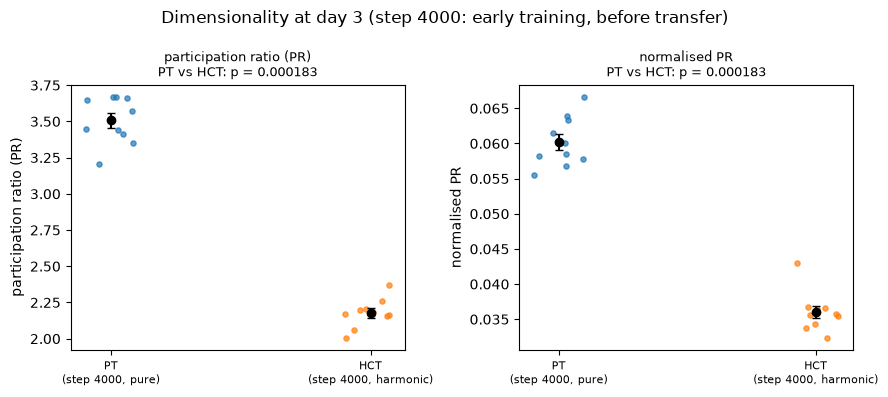

In [35]:
# ── PR at "day 3" (paper Fig. 5c: PT vs HCT early in training, before any transfer) ──
# PT-HCT is not shown: its day 3 is the PT phase, i.e. the PT network (SOURCE_RUN) itself;
# SWITCH_MODEL's own checkpoints are all after the transfer.
EARLY_PAIR = ('PT', 'HCT')
groups = [l for l in RUNS if l != SWITCH_MODEL]

early = pd.concat([df[(df['label'] == l) & (df['step'] == day3[l])] for l in groups])

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
rng = np.random.default_rng(0)
for ax, (m, title) in zip(axes, [('pr', 'participation ratio (PR)'), ('npr', 'normalised PR')]):
    for k, l in enumerate(groups):
        v = early[early['label'] == l][m].values
        ax.scatter(k + rng.uniform(-0.1, 0.1, len(v)), v, s=14, alpha=0.7)
        ax.errorbar(k, v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt='o', color='k', ms=6, capsize=3)
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels([f'{l}\n(step {day3[l]}, {RUNS[l]["task"]})' for l in groups], fontsize=8)
    ax.set_ylabel(title)
    if all(l in groups for l in EARLY_PAIR):
        a = early[early['label'] == EARLY_PAIR[0]][m].values
        b = early[early['label'] == EARLY_PAIR[1]][m].values
        p = mannwhitneyu(a, b, alternative='two-sided').pvalue
        ax.set_title(f'{title}\n{EARLY_PAIR[0]} vs {EARLY_PAIR[1]}: p = {p:.3g}', fontsize=9)
fig.suptitle(f'Dimensionality at day 3 (step {DAY3_STEP}: early training, before transfer)')
fig.tight_layout()
plt.show()

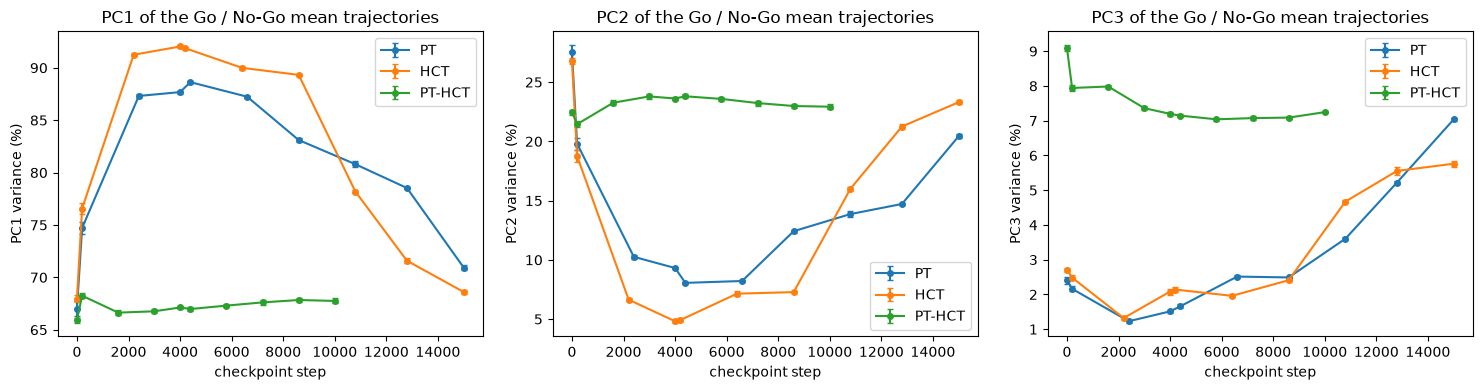

pc1_var  pc2_var  pc3_var
label  step                            
HCT    0         68.0     26.8      2.7
       200       76.6     18.8      2.5
       2200      91.2      6.6      1.3
       4000      92.0      4.8      2.1
       4200      91.9      4.9      2.1
       6400      90.0      7.1      2.0
       8600      89.3      7.3      2.4
       10800     78.2     16.0      4.7
       12800     71.6     21.3      5.6
       15000     68.6     23.3      5.8
PT     0         67.0     27.5      2.4
       200       74.7     19.8      2.2
       2400      87.3     10.3      1.2
       4000      87.7      9.3      1.5
       4400      88.6      8.1      1.7
       6600      87.2      8.2      2.5
       8600      83.1     12.4      2.5
       10800     80.8     13.9      3.6
       12800     78.5     14.7      5.2
       15000     70.9     20.4      7.0
PT-HCT 0         65.9     22.5      9.1
       200       68.3     21.5      7.9
       1600      66.6     23.3      8.0
       3000      66.8     23.8      7.4
       4000      67.1     23.6      7.2
       4400      67.0     23.8      7.1
       5800      67.3     23.6      7.0
       7200      67.6     23.2      7.1
       8600      67.8     23.0      7.1
       10000     67.8     22.9      7.2

In [36]:
# ── trajectory PCA: variance in PC1-3 over training (paper PT example: PC1 51% -> 39% -> 31%) ──
for k in range(3):
    df[f'pc{k + 1}_var'] = df['var_ratio'].apply(lambda v, k=k: 100 * v[k])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for k, ax in enumerate(axes):
    for label in RUNS:
        g = df[df['label'] == label].groupby('step')[f'pc{k + 1}_var']
        ax.errorbar(g.mean().index, g.mean().values, yerr=(g.std(ddof=1) / np.sqrt(g.count())).values,
                    marker='o', ms=4, capsize=2, label=label)
    ax.set(xlabel='checkpoint step', ylabel=f'PC{k + 1} variance (%)',
           title=f'PC{k + 1} of the Go / No-Go mean trajectories')
    ax.legend()
fig.tight_layout()
plt.show()
df.groupby(['label', 'step'])[['pc1_var', 'pc2_var', 'pc3_var']].mean().round(1)

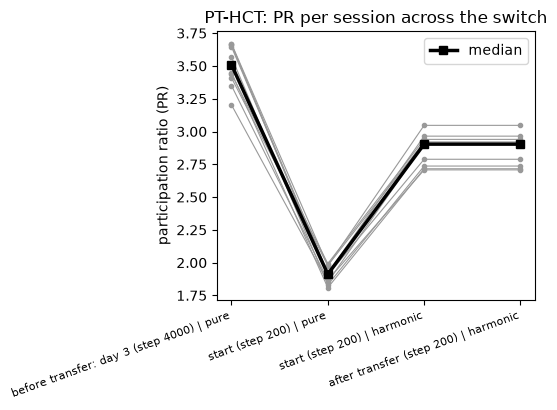

,from,to,median PR (from),median PR (to),median % change,sessions decreasing
0,before transfer: day 3 (step 4000) | pure,start (step 200) | pure,3.509228,1.911913,-46.760727,10/10
1,start (step 200) | pure,start (step 200) | harmonic,1.911913,2.903681,49.788559,0/10
2,start (step 200) | harmonic,after transfer (step 200) | harmonic,2.903681,2.903681,0.000000,0/10


In [37]:
# ── before / after the switch, paired by session (paper Fig. 5d) ───────────────
# sessions are paired by their simulation seed (same index = same seed); the paper pairs
# by mouse, which is a stronger pairing than this
names = list(df_switch['label'].unique())
piv = df_switch.pivot(index='session', columns='label', values='pr')[names].dropna()

fig, ax = plt.subplots(figsize=(5.5, 4.2))
for _, r in piv.iterrows():
    ax.plot(range(len(names)), r.values, '-o', color='0.6', ms=3, lw=0.8)
ax.plot(range(len(names)), piv.median().values, '-s', color='k', lw=2.5, label='median')
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=20, ha='right', fontsize=8)
ax.set(ylabel='participation ratio (PR)', title=f'{SWITCH_MODEL}: PR per session across the switch')
ax.legend()
fig.tight_layout()
plt.show()

chg = []
for a_, b_ in zip(names[:-1], names[1:]):
    pct = 100 * (piv[b_] - piv[a_]) / piv[a_]
    chg.append({'from': a_, 'to': b_, 'median PR (from)': piv[a_].median(),
                'median PR (to)': piv[b_].median(), 'median % change': pct.median(),
                'sessions decreasing': f'{int((piv[b_] < piv[a_]).sum())}/{len(piv)}'})
pd.DataFrame(chg)

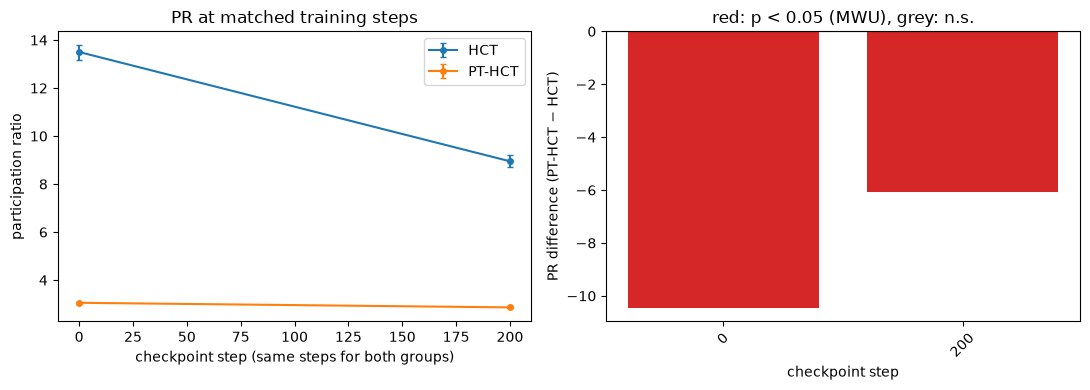

,HCT,PT-HCT,PT-HCT - HCT,p (MWU)
step,,,,
0,13.500698,3.054276,-10.446422,0.000183
200,8.948709,2.862794,-6.085915,0.000183


In [38]:
# ── same-step comparison: the paper compares groups at the same training day ────
dirs = [RUNS[GROUP_A]['model_dir'], RUNS[GROUP_B]['model_dir']]
cs = pg.common_steps(dirs, n=N_STEPS,
                     max_step=min(comparison_step(GROUP_A), comparison_step(GROUP_B)))
rows_m = []
for l in (GROUP_A, GROUP_B):
    rows_m += pg.run_condition(l, RUNS[l]['model_dir'], RUNS[l]['task'], cs, verbose=False, **kw)
dm = pd.DataFrame(rows_m)

table = []
for s in cs:
    a_ = dm[(dm['label'] == GROUP_A) & (dm['step'] == s)]['pr'].values
    b_ = dm[(dm['label'] == GROUP_B) & (dm['step'] == s)]['pr'].values
    table.append({'step': s, GROUP_A: a_.mean(), GROUP_B: b_.mean(),
                  f'{GROUP_B} - {GROUP_A}': b_.mean() - a_.mean(),
                  'p (MWU)': mannwhitneyu(b_, a_, alternative='two-sided').pvalue})
tab = pd.DataFrame(table).set_index('step')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for l in (GROUP_A, GROUP_B):
    g = dm[dm['label'] == l].groupby('step')['pr']
    axes[0].errorbar(g.mean().index, g.mean().values, yerr=(g.std(ddof=1) / np.sqrt(g.count())).values,
                     marker='o', ms=4, capsize=2, label=l)
axes[0].set(xlabel='checkpoint step (same steps for both groups)', ylabel='participation ratio',
            title='PR at matched training steps')
axes[0].legend()
axes[1].bar(range(len(tab)), tab.iloc[:, 2].values,
            color=['tab:red' if p < 0.05 else 'tab:gray' for p in tab['p (MWU)']])
axes[1].set_xticks(range(len(tab))); axes[1].set_xticklabels(tab.index, rotation=45)
axes[1].axhline(0, color='k', lw=0.8)
axes[1].set(xlabel='checkpoint step', ylabel=f'PR difference ({GROUP_B} − {GROUP_A})',
            title='red: p < 0.05 (MWU), grey: n.s.')
fig.tight_layout()
plt.show()
tab

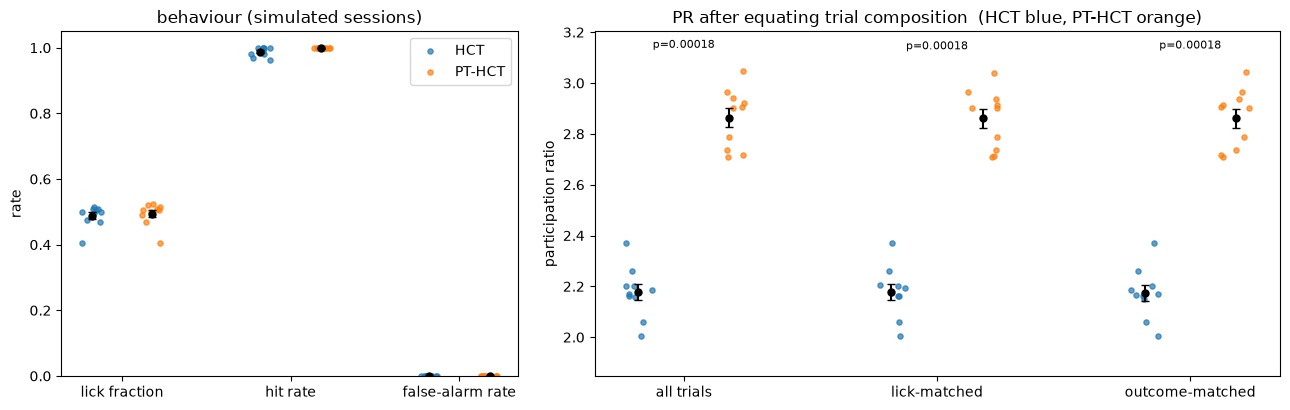

,HCT,PT-HCT,PT-HCT - HCT,p (MWU),n sessions
comparison,,,,,
all trials,2.177056,2.862794,0.685738,0.000183,10
lick-matched,2.178579,2.860795,0.682217,0.000183,10
outcome-matched,2.172296,2.861466,0.689170,0.000183,10


In [39]:
# ── behaviour and outcome-matched PR (paper Supp. Fig. 6) ──────────────────────
# Do the groups respond (lick) on a similar fraction of trials, and does the PR difference
# survive when trials are subsampled to equate lick / outcome composition?
cmp_labels = (GROUP_A, GROUP_B)
rows_t = {l: pg.run_condition(l, RUNS[l]['model_dir'], RUNS[l]['task'], [comparison_step(l)],
                              keep_trials=True, verbose=False, **kw) for l in cmp_labels}
ra, rb = rows_t[GROUP_A], rows_t[GROUP_B]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1, 1.5]})
rng = np.random.default_rng(0)
cols = ['C0', 'C1']

ax = axes[0]
beh = [('lick_frac', 'lick fraction'), ('hit', 'hit rate'), ('fa', 'false-alarm rate')]
for k, (key, name) in enumerate(beh):
    for g, l in enumerate(cmp_labels):
        v = np.array([r[key] for r in rows_t[l]])
        x = k + (g - 0.5) * 0.36
        ax.scatter(x + rng.uniform(-0.06, 0.06, len(v)), v, s=14, color=cols[g], alpha=0.7,
                   label=l if k == 0 else None)
        ax.errorbar(x, v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt='o', color='k', ms=5, capsize=3)
ax.set_xticks(range(len(beh))); ax.set_xticklabels([n for _, n in beh])
ax.set(ylabel='rate', ylim=(0, 1.05), title='behaviour (simulated sessions)')
ax.legend()

# PR: all trials vs lick-matched vs outcome-matched (Hit / Miss / FA / CR counts equated)
ax = axes[1]
conds = {'all trials': ([r['pr'] for r in ra], [r['pr'] for r in rb])}
for by in ('lick', 'outcome'):
    a_, b_, n_ = pg.matched_pr(ra, rb, by=by)
    conds[f'{by}-matched'] = (a_, b_)
table = []
for k, (name, (a_, b_)) in enumerate(conds.items()):
    a_, b_ = np.asarray(a_), np.asarray(b_)
    if len(a_) < 2:
        continue
    for g, v in enumerate([a_, b_]):
        x = k + (g - 0.5) * 0.36
        ax.scatter(x + rng.uniform(-0.06, 0.06, len(v)), v, s=14, color=cols[g], alpha=0.7)
        ax.errorbar(x, v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt='o', color='k', ms=5, capsize=3)
    p = mannwhitneyu(b_, a_, alternative='two-sided').pvalue
    ax.text(k, max(a_.max(), b_.max()) * 1.03, f'p={p:.2g}', ha='center', fontsize=8)
    table.append({'comparison': name, GROUP_A: a_.mean(), GROUP_B: b_.mean(),
                  f'{GROUP_B} - {GROUP_A}': b_.mean() - a_.mean(), 'p (MWU)': p, 'n sessions': len(a_)})
ax.set_xticks(range(len(conds))); ax.set_xticklabels(list(conds)); ax.margins(y=0.15)
ax.set(ylabel='participation ratio', title=f'PR after equating trial composition  ({GROUP_A} blue, {GROUP_B} orange)')
fig.tight_layout()
plt.show()
pd.DataFrame(table).set_index('comparison')

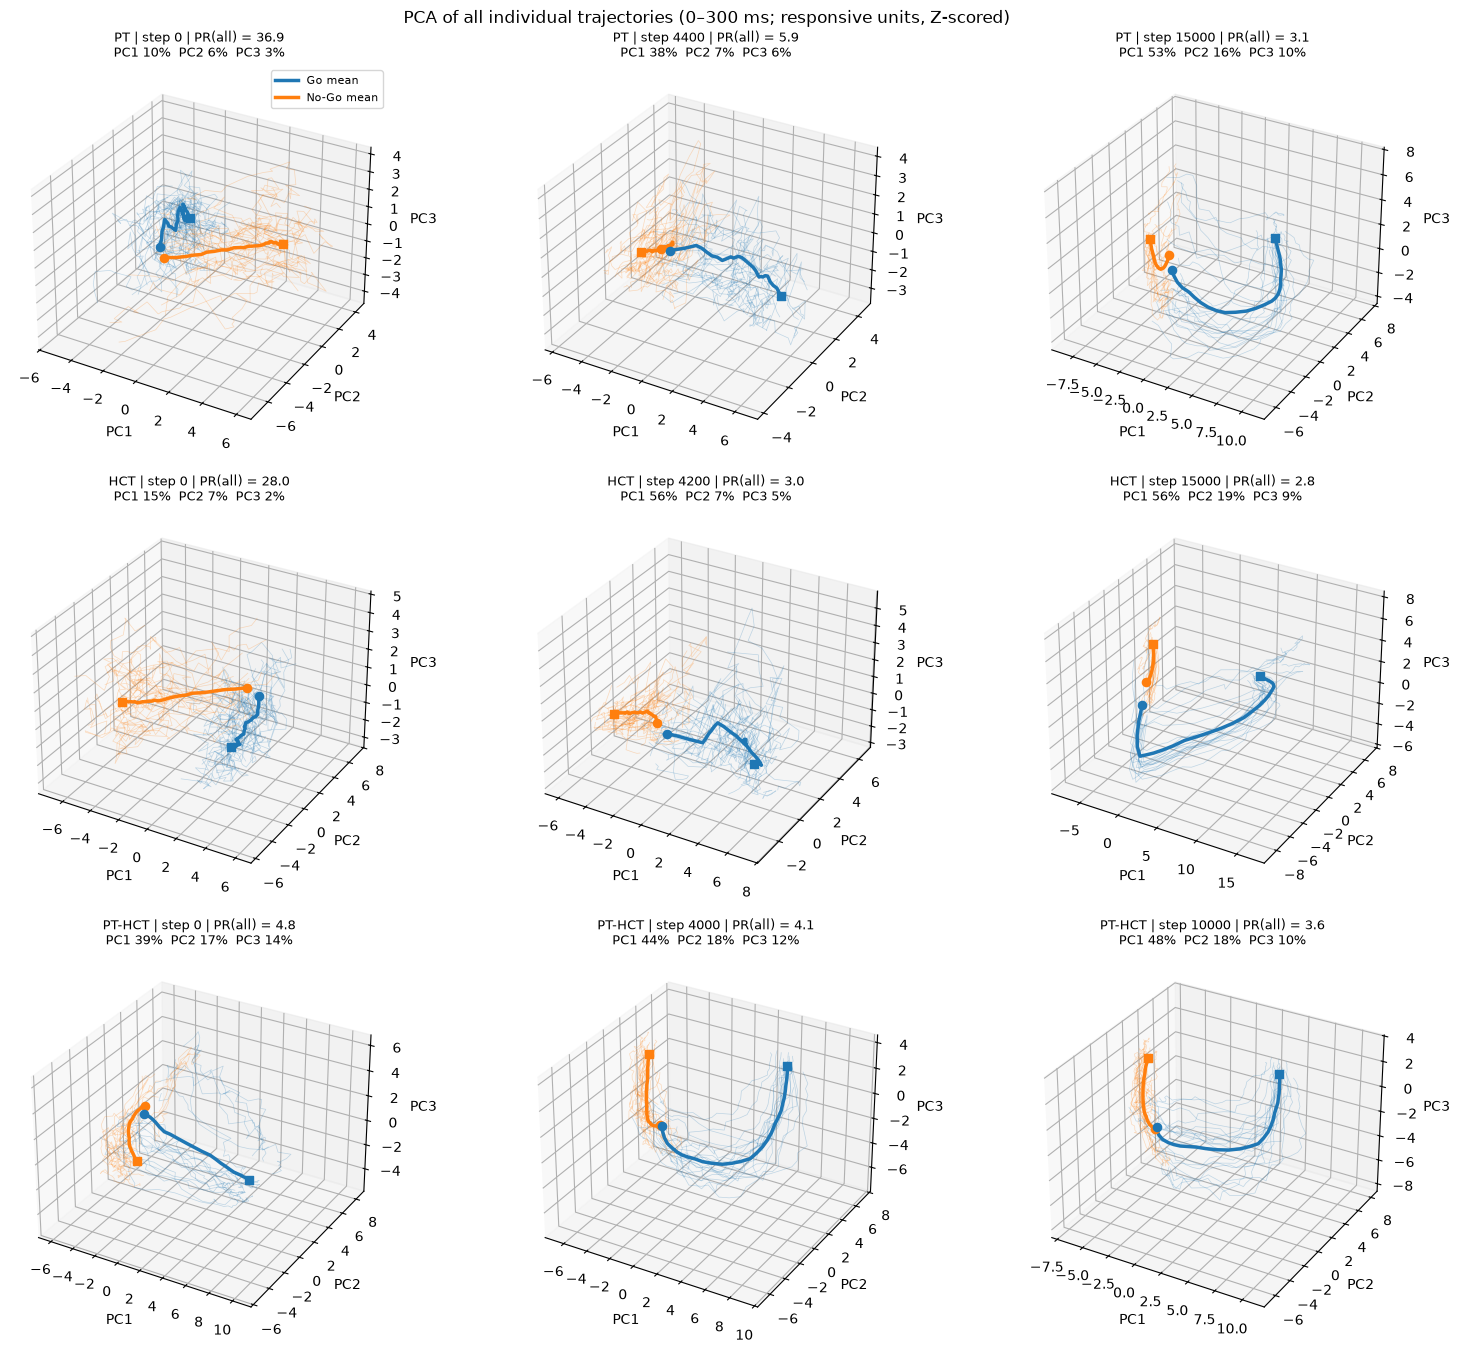

In [40]:
# ── PCA on ALL simulated trajectories (every individual noisy trial) ───────────────────────────
# One observation = one time sample of one trial in the analysis window. Thin lines: single trials
# (N_SHOW_TRIALS per class); thick lines: Go / No-Go mean trajectories, projected into the same
# PC space. Compare with the mean-trajectory PCA above, which only sees the two mean trajectories.
fig = plt.figure(figsize=(5.2 * SHOW, 4.6 * len(RUNS)))
for i, label in enumerate(RUNS):
    d = df[df['label'] == label]
    steps_l = sorted(d['step'].unique())
    show_steps = [steps_l[j] for j in np.unique(np.round(np.linspace(0, len(steps_l) - 1, SHOW)).astype(int))]
    for j, step in enumerate(show_steps):
        r = d[d['step'] == step].iloc[0]
        ax = fig.add_subplot(len(RUNS), SHOW, i * SHOW + j + 1, projection='3d')
        for trials, col in [(r['proj_trials_go'], 'tab:blue'), (r['proj_trials_nogo'], 'tab:orange')]:
            for tr in trials:
                ax.plot(tr[:, 0], tr[:, 1], tr[:, 2], color=col, lw=0.5, alpha=0.25)
        for proj, col, lab in [(r['proj_go_all'], 'tab:blue', 'Go'), (r['proj_nogo_all'], 'tab:orange', 'No-Go')]:
            ax.plot(proj[:, 0], proj[:, 1], proj[:, 2], color=col, lw=2.5, label=f'{lab} mean')
            ax.scatter(*proj[0], color=col, marker='o', s=35)      # circle = onset
            ax.scatter(*proj[-1], color=col, marker='s', s=35)     # square = end of window
        v = r['var_ratio_all'] * 100
        ax.set_title(f'{label} | step {step} | PR(all) = {r["pr_all"]:.1f}\n'
                     f'PC1 {v[0]:.0f}%  PC2 {v[1]:.0f}%  PC3 {v[2]:.0f}%', fontsize=9)
        ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_zlabel('PC3')
        if i == 0 and j == 0:
            ax.legend(fontsize=8)
fig.suptitle(f'PCA of all individual trajectories ({WINDOW_MS[0]}–{WINDOW_MS[1]} ms; responsive units, Z-scored)')
fig.tight_layout()
plt.show()

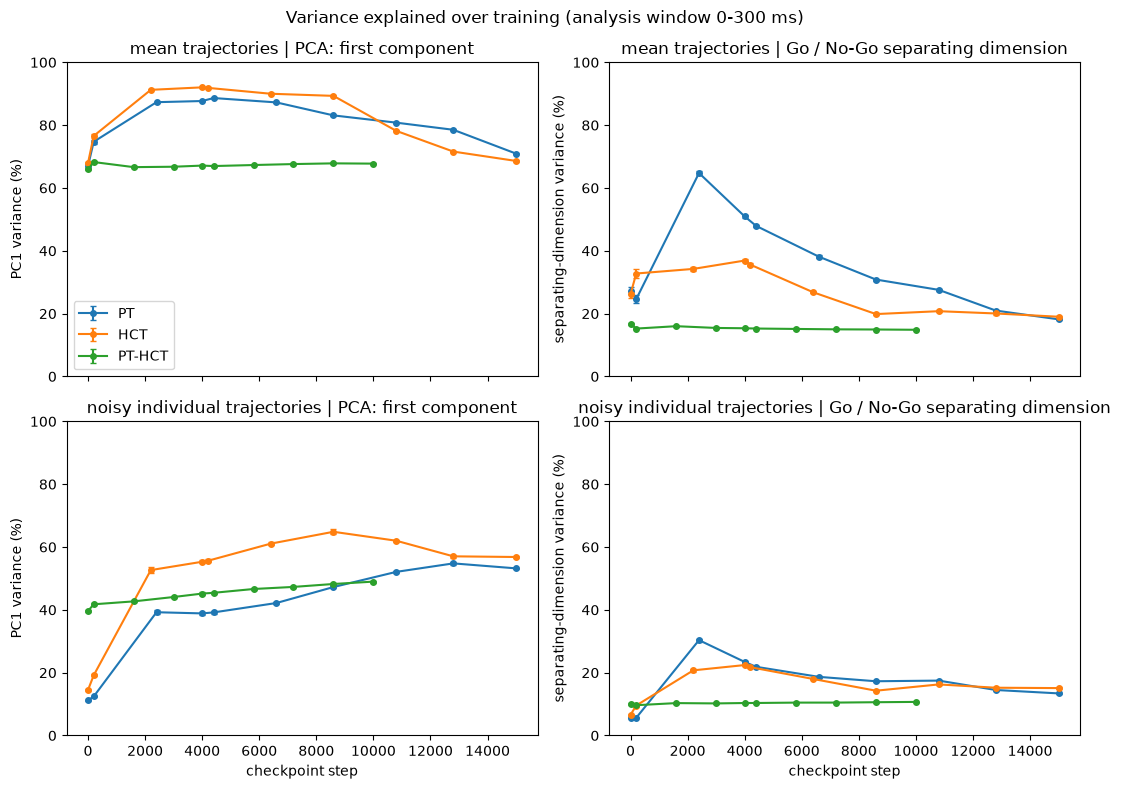

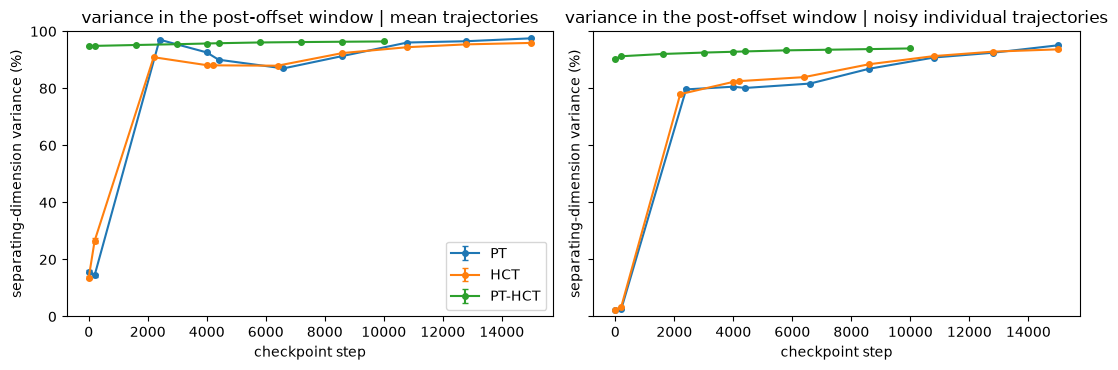

pc1_mean  sep_var_mean_pct  pc1_all  sep_var_all_pct  \
label  step                                                          
HCT    0         67.97             26.16    14.51             6.58   
       200       76.57             32.77    19.17             9.55   
       2200      91.25             34.23    52.66            20.74   
       4000      92.04             36.89    55.31            22.42   
       4200      91.87             35.58    55.62            21.75   
       6400      90.00             26.80    61.08            18.00   
       8600      89.33             19.86    64.85            14.26   
       10800     78.19             20.78    62.01            16.26   
       12800     71.59             20.05    57.04            15.21   
       15000     68.60             19.00    56.83            15.09   
PT     0         66.99             27.35    11.17             5.67   
       200       74.72             24.61    12.43             5.63   
       2400      87.32             64.76    39.24            30.36   
       4000      87.68             50.94    38.87            23.42   
       4400      88.63             47.93    39.18            21.87   
       6600      87.24             38.13    42.18            18.67   
       8600      83.11             30.85    47.26            17.27   
       10800     80.80             27.57    52.09            17.48   
       12800     78.53             20.97    54.79            14.49   
       15000     70.94             18.18    53.21            13.40   
PT-HCT 0         65.92             16.67    39.65            10.02   
       200       68.25             15.24    41.77             9.64   
       1600      66.64             16.00    42.70            10.31   
       3000      66.76             15.44    44.09            10.21   
       4000      67.13             15.34    45.18            10.34   
       4400      66.98             15.25    45.43            10.35   
       5800      67.31             15.12    46.64            10.47   
       7200      67.61             15.00    47.30            10.48   
       8600      67.84             14.94    48.24            10.59   
       10000     67.75             14.86    48.99            10.69   

              sep_var_all_post_pct  pr_all  sep_pc1_cos  
label  step                                              
HCT    0                      2.28   27.28         0.71  
       200                    3.36   19.21         0.70  
       2200                  77.97    3.44         0.61  
       4000                  82.27    3.11         0.62  
       4200                  82.54    3.08         0.61  
       6400                  83.94    2.58         0.52  
       8600                  88.45    2.32         0.44  
       10800                 91.32    2.43         0.47  
       12800                 92.88    2.72         0.45  
       15000                 93.68    2.70         0.44  
PT     0                      2.22   35.23         0.75  
       200                    2.54   29.84         0.68  
       2400                  79.64    5.85         0.87  
       4000                  80.59    5.74         0.76  
       4400                  80.14    5.62         0.73  
       6600                  81.68    4.90         0.64  
       8600                  86.87    4.02         0.58  
       10800                 90.82    3.39         0.55  
       12800                 92.49    3.06         0.47  
       15000                 95.10    3.09         0.43  
PT-HCT 0                     90.38    4.71         0.44  
       200                   91.26    4.30         0.42  
       1600                  92.06    4.14         0.42  
       3000                  92.55    4.01         0.40  
       4000                  92.83    3.89         0.40  
       4400                  92.96    3.87         0.40  
       5800                  93.33    3.73         0.39  
       7200                  93.55    3.67         0.39  
       8600                  93.7

In [41]:
# ── 2 x 2 summary over training ────────────────────────────────────────────────────────────────
#   columns : PC1 variance (the existing dimensionality measure)  |  variance along the Go / No-Go
#             separating dimension
#   rows    : Go / No-Go MEAN trajectories                         |  noisy INDIVIDUAL trajectories
# Separating dimension = direction of the Go - No-Go mean difference found AFTER stimulus offset
# (SEP_AFTER_OFF_MS). Its variance is evaluated on the analysis window WINDOW_MS; the direction is
# fitted on one half of the trials and the variance measured on the other half (and vice versa).
df['pc1_mean'] = df['var_ratio'].apply(lambda v: 100 * v[0])
df['pc1_all']  = df['var_ratio_all'].apply(lambda v: 100 * v[0])
for k in ('sep_var_mean', 'sep_var_all', 'sep_var_mean_post', 'sep_var_all_post'):
    df[k + '_pct'] = 100 * df[k]

grid = [[('pc1_mean', 'PC1 variance (%)'), ('sep_var_mean_pct', 'separating-dimension variance (%)')],
        [('pc1_all',  'PC1 variance (%)'), ('sep_var_all_pct',  'separating-dimension variance (%)')]]
row_titles = ['mean trajectories', 'noisy individual trajectories']
col_titles = ['PCA: first component', 'Go / No-Go separating dimension']

def curve(ax, key, data=None):
    data = df if data is None else data
    for label in RUNS:
        g = data[data['label'] == label].groupby('step')[key]
        ax.errorbar(g.mean().index, g.mean().values, yerr=(g.std(ddof=1) / np.sqrt(g.count())).values,
                    marker='o', ms=4, capsize=2, label=label)

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
for r_i in range(2):
    for c_i in range(2):
        key, ylab = grid[r_i][c_i]
        ax = axes[r_i, c_i]
        curve(ax, key)
        ax.set(ylabel=ylab, ylim=(0, 100), title=f'{row_titles[r_i]} | {col_titles[c_i]}')
        if r_i == 1:
            ax.set_xlabel('checkpoint step')
axes[0, 0].legend()
fig.suptitle(f'Variance explained over training (analysis window {WINDOW_MS[0]}-{WINDOW_MS[1]} ms)')
fig.tight_layout()
plt.show()

# the same separating dimension, evaluated within the post-offset window itself
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (key, ttl) in zip(axes, [('sep_var_mean_post_pct', 'mean trajectories'),
                                 ('sep_var_all_post_pct', 'noisy individual trajectories')]):
    curve(ax, key)
    ax.set(xlabel='checkpoint step', ylabel='separating-dimension variance (%)', ylim=(0, 100),
           title=f'variance in the post-offset window | {ttl}')
axes[0].legend()
fig.tight_layout()
plt.show()

(df.groupby(['label', 'step'])[['pc1_mean', 'sep_var_mean_pct', 'pc1_all', 'sep_var_all_pct',
                                'sep_var_all_post_pct', 'pr_all', 'sep_pc1_cos']].mean().round(2))

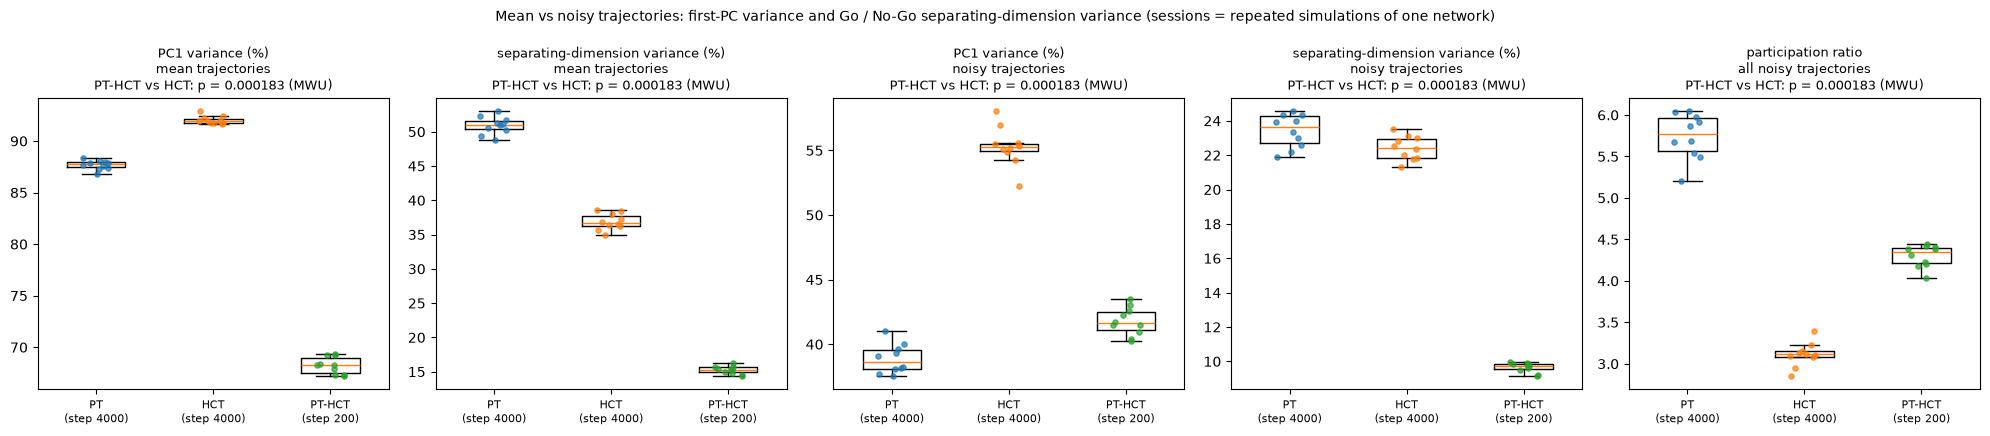

,HCT,PT-HCT,PT-HCT - HCT,p_mannwhitney
metric,,,,
pc1_mean,92.036119,68.253990,-23.782129,0.000183
sep_var_mean_pct,36.894122,15.238092,-21.656030,0.000183
pc1_all,55.311127,41.770792,-13.540334,0.000183
sep_var_all_pct,22.423716,9.644248,-12.779468,0.000183
pr_all,3.111940,4.299209,1.187269,0.000183


In [42]:
# ── group comparison at each model's comparison checkpoint: the four measures of the 2 x 2 grid
#    (PC1 variance / separating-dimension variance, for mean and noisy trajectories) + PR of all trajectories ──
last_step = {l: comparison_step(l) for l in RUNS}
dfl2 = pd.concat([df[(df['label'] == l) & (df['step'] == last_step[l])] for l in RUNS])

metrics2 = [('pc1_mean',         'PC1 variance (%)\nmean trajectories'),
            ('sep_var_mean_pct', 'separating-dimension variance (%)\nmean trajectories'),
            ('pc1_all',          'PC1 variance (%)\nnoisy trajectories'),
            ('sep_var_all_pct',  'separating-dimension variance (%)\nnoisy trajectories'),
            ('pr_all',           'participation ratio\nall noisy trajectories')]
labels = list(RUNS)
fig, axes = plt.subplots(1, len(metrics2), figsize=(4.0 * len(metrics2), 4.4))
stat2 = []
for ax, (m, title) in zip(axes, metrics2):
    data = [dfl2[dfl2['label'] == l][m].values for l in labels]
    ax.boxplot(data, positions=range(len(labels)), widths=0.5, showfliers=False)
    rng = np.random.default_rng(0)
    for k, v in enumerate(data):
        ax.scatter(k + rng.uniform(-0.12, 0.12, len(v)), v, s=14, alpha=0.7, zorder=3)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels([f'{l}\n(step {last_step[l]})' for l in labels], fontsize=8)
    a = dfl2[dfl2['label'] == GROUP_A][m].values
    b = dfl2[dfl2['label'] == GROUP_B][m].values
    p_u = mannwhitneyu(b, a, alternative='two-sided').pvalue
    stat2.append(dict(metric=m, **{GROUP_A: a.mean(), GROUP_B: b.mean()},
                      **{f'{GROUP_B} - {GROUP_A}': b.mean() - a.mean()}, p_mannwhitney=p_u))
    ax.set_title(f'{title}\n{GROUP_B} vs {GROUP_A}: p = {p_u:.3g} (MWU)', fontsize=9)
fig.suptitle('Mean vs noisy trajectories: first-PC variance and Go / No-Go separating-dimension variance '
             '(sessions = repeated simulations of one network)', fontsize=10)
fig.tight_layout()
plt.show()
pd.DataFrame(stat2).set_index('metric')